=== EHT (M87*) Event Horizon Phase-Shear Simulation ===
1. M87* Schwarzschild Radius (R_s)       = 128.34 AU
2. Current EHT Upper Bound (0.1 R_s)     = 12.83 AU
3. Sub-AU Regime (lambda=0.1 AU, xi=5)   = 0.50 AU (Resolvable by Space-VLBI)


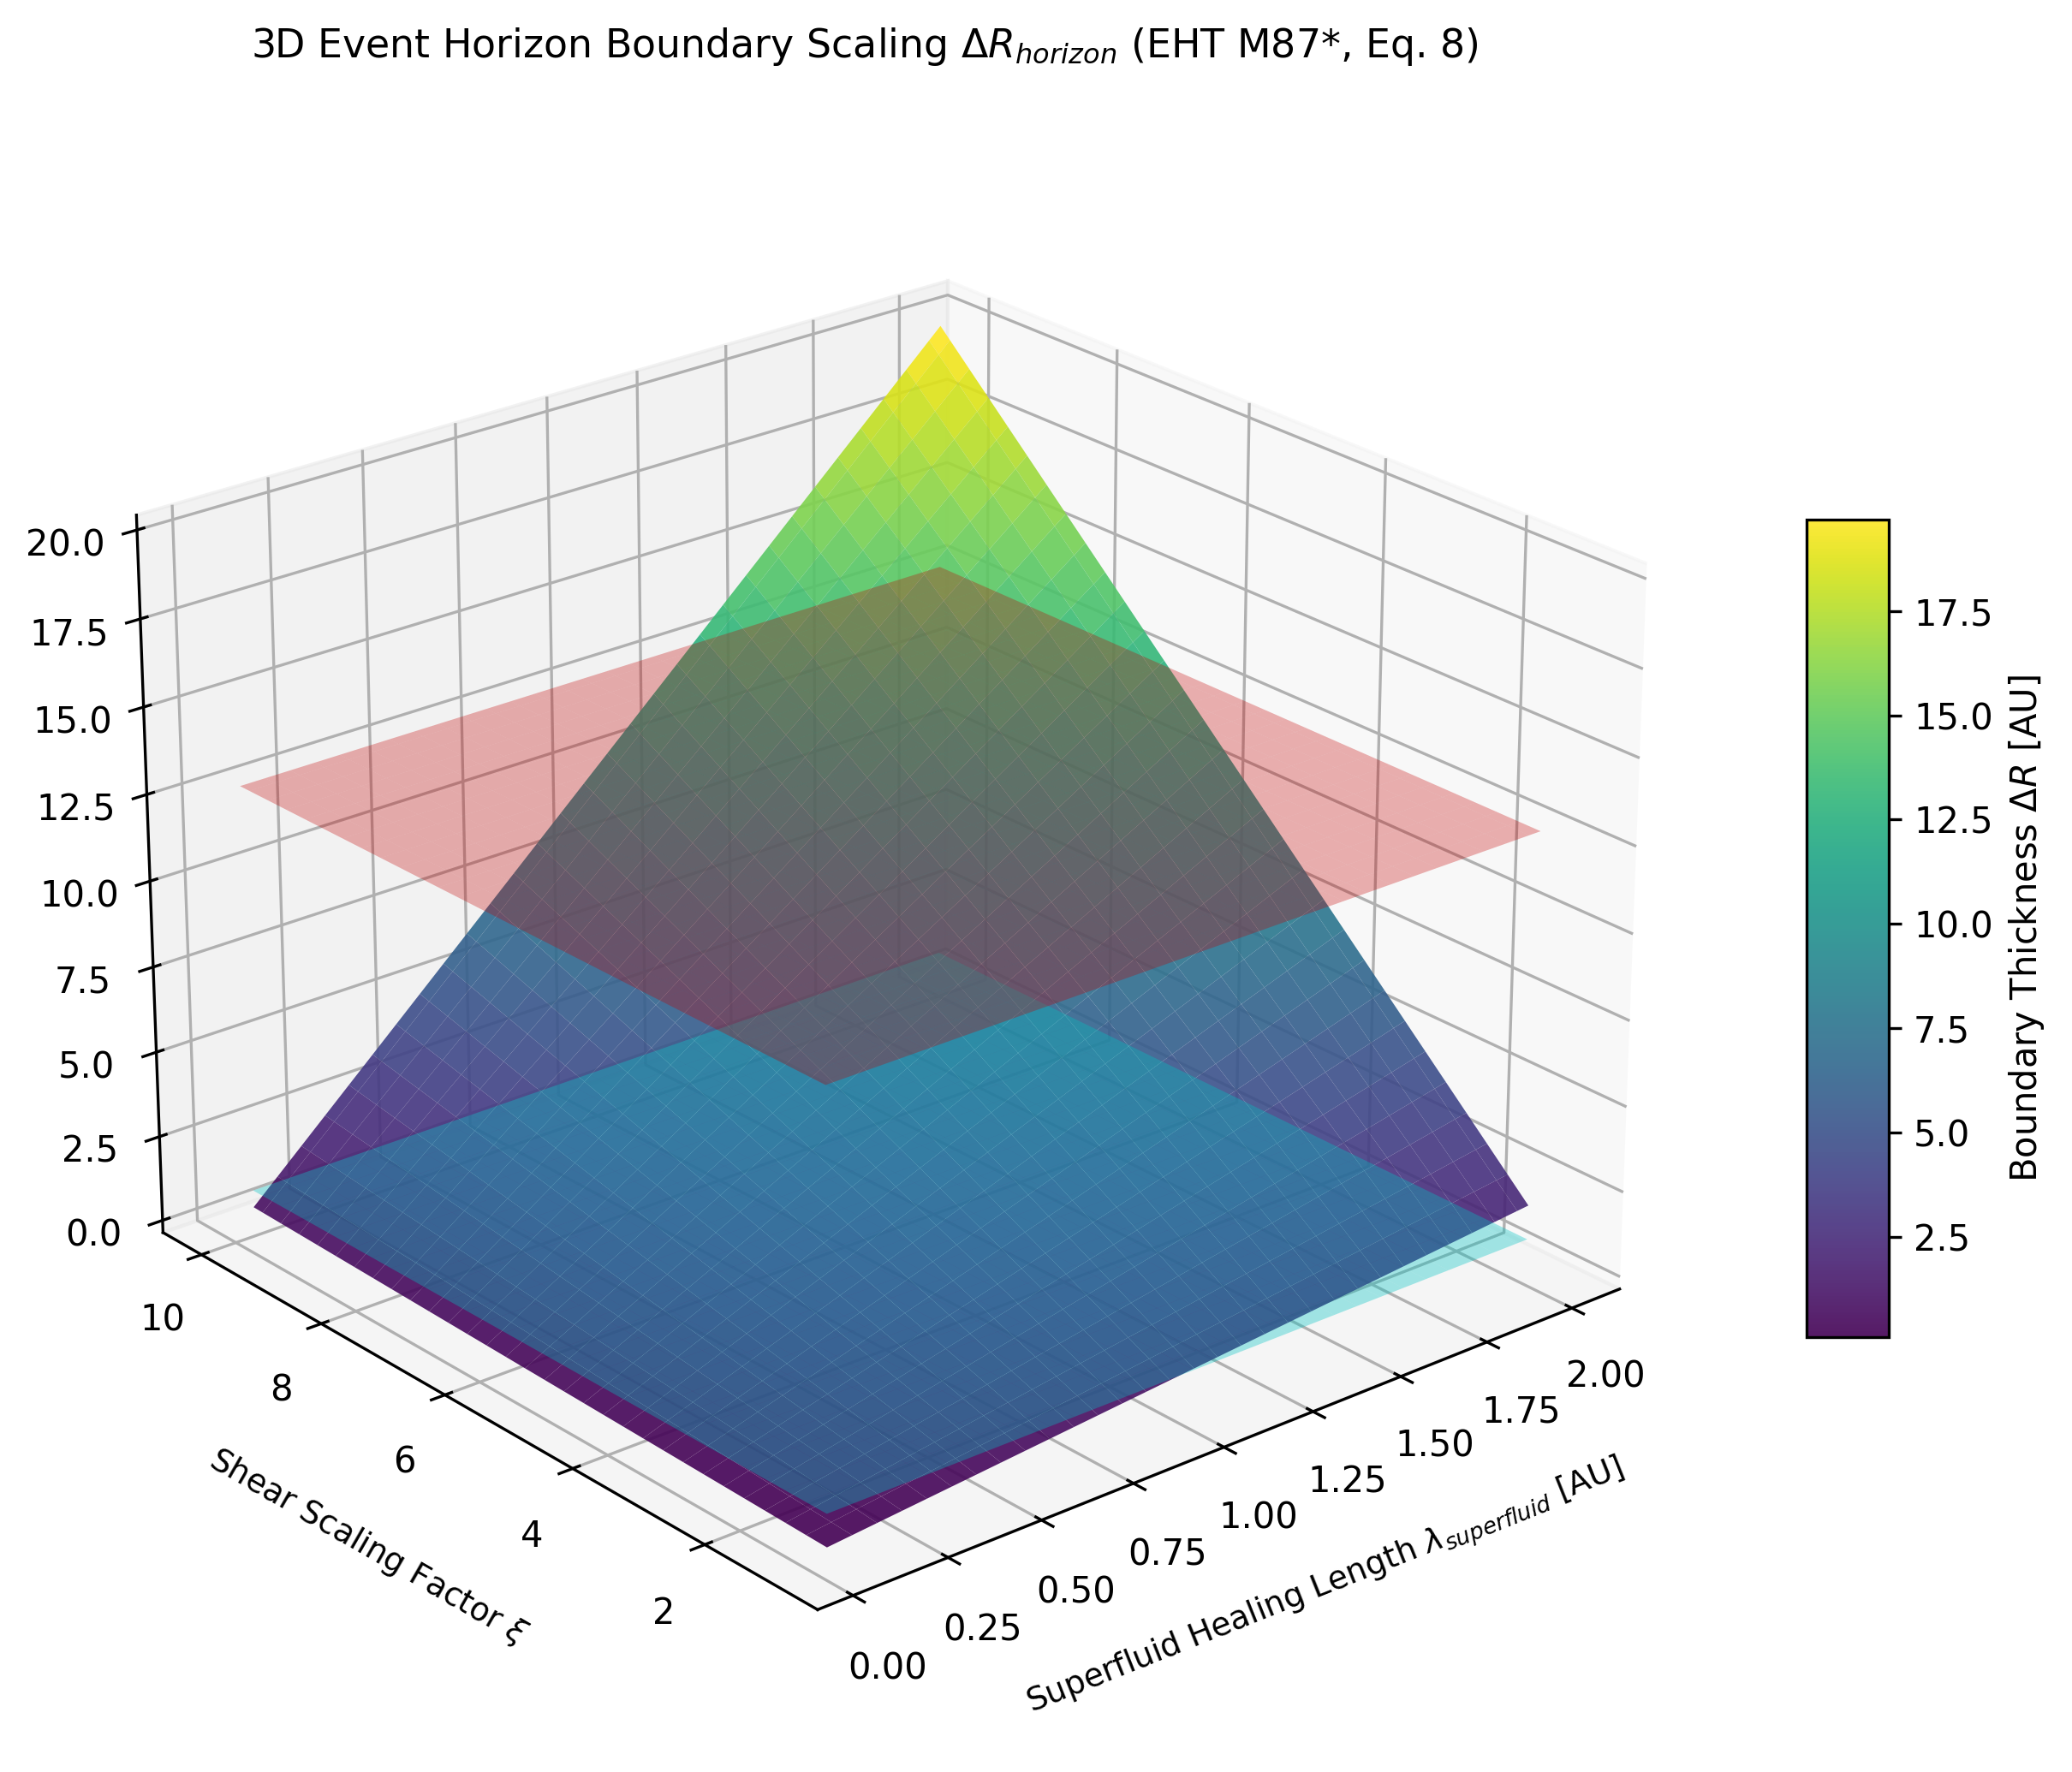

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# الثوابت الرصدية لثقب M87* الأسود من تلسكوب أفق الحدث (EHT)
Rs_m = 1.92e13          # نصف قطر شفارتزشيلد بالمتر
AU_m = 1.496e11         # الوحدة الفلكية بالمتر
Rs_AU = Rs_m / AU_m     # نصف قطر شفارتزشيلد بالوحدة الفلكية (~128.3 AU)
eht_limit_AU = 0.1 * Rs_AU  # الحد الأعلى الرصدي لسمك حلقة القص الطوري (~12.83 AU)

# شبكة المحاكاة ثلاثية الأبعاد:
# المحور X: طول التئام المائع الفائق (lambda_superfluid) بالوحدة الفلكية (AU)
lambda_sf = np.linspace(0.05, 2.0, 60)
# المحور Y: معامل القص اللابعدي (xi)
xi_factor = np.linspace(1.0, 10.0, 60)
L_SF, XI = np.meshgrid(lambda_sf, xi_factor)

# حساب سماكة منطقة القص الطوري عند أفق الحدث طبقاً للمعادلة (8):
Delta_R_AU = XI * L_SF

# طباعة النتائج الرقمية للمقارنة المباشرة
print("=== EHT (M87*) Event Horizon Phase-Shear Simulation ===")
print(f"1. M87* Schwarzschild Radius (R_s)       = {Rs_AU:.2f} AU")
print(f"2. Current EHT Upper Bound (0.1 R_s)     = {eht_limit_AU:.2f} AU")
print(f"3. Sub-AU Regime (lambda=0.1 AU, xi=5)   = {0.1 * 5:.2f} AU (Resolvable by Space-VLBI)")

# الرسم الثلاثي الأبعاد
fig = plt.figure(figsize=(10, 7), dpi=300)
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(L_SF, XI, Delta_R_AU, cmap='viridis', edgecolor='none', alpha=0.90)

# مستوى الحد الأعلى الحالي لتلسكوب EHT (~12.83 AU)
eht_plane = np.full_like(Delta_R_AU, eht_limit_AU)
ax.plot_surface(L_SF, XI, eht_plane, color='red', alpha=0.30)

# مستوى عتبة الرصد الفضائي المستقبلي (1.0 AU - Space VLBI)
vlbi_plane = np.full_like(Delta_R_AU, 1.0)
ax.plot_surface(L_SF, XI, vlbi_plane, color='cyan', alpha=0.35)

ax.set_title('3D Event Horizon Boundary Scaling $\\Delta R_{horizon}$ (EHT M87*, Eq. 8)', fontsize=11, pad=15)
ax.set_xlabel('Superfluid Healing Length $\\lambda_{superfluid}$ [AU]', fontsize=9, labelpad=10)
ax.set_ylabel('Shear Scaling Factor $\\xi$', fontsize=9, labelpad=10)
ax.set_zlabel('Horizon Thickness $\\Delta R_{horizon}$ [AU]', fontsize=9, labelpad=10)

fig.colorbar(surf, shrink=0.5, aspect=10, label='Boundary Thickness $\\Delta R$ [AU]')
ax.view_init(elev=24, azim=-130)

plt.tight_layout()
plt.savefig('sim6_3d_eht_horizon.png', dpi=300)
plt.show()